In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import iv, kv
from scipy.integrate import cumulative_trapezoid
from scipy.constants import G, c#

/var/folders/0m/t386dwn50_j7yhqjjt0_4mtm0000gq/T/ipykernel_86596/856206775.py:111: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  I1 = np.trapz(integrand1, r_slice)
/var/folders/0m/t386dwn50_j7yhqjjt0_4mtm0000gq/T/ipykernel_86596/856206775.py:112: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  I2 = np.trapz(integrand2, r_slice)


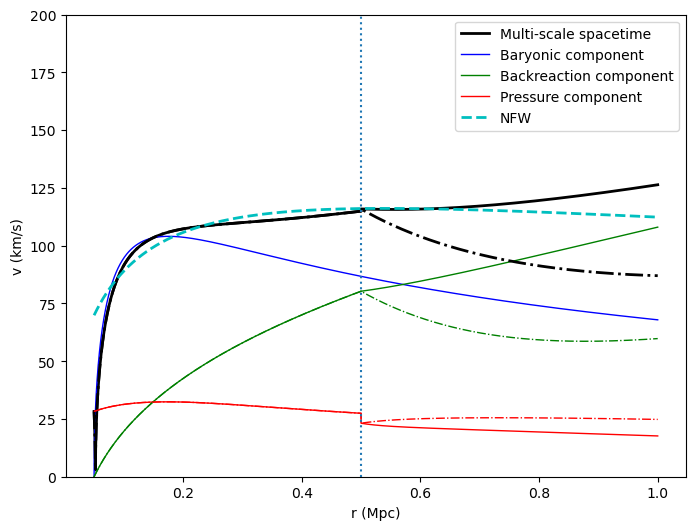

In [2]:


# ============================================================
# Units
# ============================================================

M_sun = 1.988e30
Mpc   = 3.086e22

# ============================================================
# Model parameters
# ============================================================

r_star = 0.5 * Mpc
r_ini  = 0.05 * Mpc

M_clus = 1.5e12 * M_sun


a_minus = 0.1 * Mpc
a_plus  = 0.1 * Mpc

kappa = 8*np.pi*G

# velocity dispersions
sigma_T_minus = 20e3
sigma_T_plus  = 20e3

sigma1D_minus = sigma_T_minus
sigma1D_plus  = sigma_T_plus

# ============================================================
# Radial grids
# ============================================================

r_minus = np.logspace(np.log10(r_ini), np.log10(r_star), 1000)
r_plus  = np.logspace(np.log10(r_star), np.log10(2*r_star), 1000)

# ============================================================
# Hernquist density
# ============================================================

def rho_hernquist(r, M, a):
    return (M/(2*np.pi)) * (a/(r*(r+a)**3))

rho_minus = rho_hernquist(r_minus, M_clus, a_minus)
rho_plus  = rho_hernquist(r_plus,  M_clus, a_plus)

# ============================================================
# Log derivative baryonic density
# ============================================================

def dln_rho_m(r,a):
    return -(4*r + a)/(r+a)

# ============================================================
# Baryonic gravitational potential
# ============================================================

def Phi_m(r,M,a):
    return -G*M/(r+a)

# ============================================================
# Baryonic gradient
# ============================================================

def dPhi_m_minus(r):

    term1 = (r_ini**2/r**2) * 0
    term2 = G*M_clus*a_minus*((2*r_ini+a_minus)/(r_ini+a_minus)**2 -
                              (2*r+a_minus)/(r+a_minus)**2)/r**2

    return term1 + term2


def dPhi_m_plus(r):

    dPhi_boundary = dPhi_m_minus(r_star)

    term1 = (r_star**2/r**2)*dPhi_boundary
    term2 = G*M_clus*a_plus*((2*r_star+a_plus)/(r_star+a_plus)**2 -
                              (2*r+a_plus)/(r+a_plus)**2)/r**2

    return term1 + term2

# ============================================================
# Homogeneous solutions
# ============================================================

def g1(r):
    x = 2*np.sqrt(r/r_star)
    return 2*np.sqrt(r/r_star)*iv(1,x)

def g2(r):
    x = 2*np.sqrt(r/r_star)
    return 2*np.sqrt(r/r_star)*kv(1,x)

# ============================================================
# Particular solution integrals
# ============================================================

def compute_gp(r,a):

    gp = np.zeros_like(r)

    for i in range(len(r)):

        r_slice = r[:i+1]

        integrand1 = g2(r_slice)*r_slice/(r_slice+a)**2
        integrand2 = g1(r_slice)*r_slice/(r_slice+a)**2

        I1 = np.trapz(integrand1, r_slice)
        I2 = np.trapz(integrand2, r_slice)

        gp[i] = (G*M_clus/2)*(g1(r[i])*I1 - g2(r[i])*I2)

    return gp

gp_minus = compute_gp(r_minus,a_minus)
gp_plus  = compute_gp(r_plus,a_plus)

# ============================================================
# Interior constants
# ============================================================

g1_ini = g1(r_ini)

A_minus = -gp_minus[0]/g1_ini
B_minus = 0.0

# ============================================================
# Backreaction gradient
# ============================================================

def dPhi_hat(r,A,B,gp):

    return (A*g1(r) + B*g2(r) + gp)/r**2

dPhi_hat_minus = dPhi_hat(r_minus,A_minus,B_minus,gp_minus)

# ============================================================
# Interior potential
# ============================================================

Phi_hat_minus = cumulative_trapezoid(dPhi_hat_minus,r_minus,initial=0)

# ============================================================
# Matching conditions
# ============================================================

Phi_hat_star = Phi_hat_minus[-1]
dPhi_hat_star = dPhi_hat_minus[-1]

A_plus1 = 0.0

B_plus1 = (r_star**2*dPhi_hat_star - gp_plus[0])/(2.0*kv(1,2))

A_plus = (r_star**2*dPhi_hat_star - gp_plus[0])/(2.0*iv(1,2))

B_plus = 0.0 #(r_star**2*dPhi_hat_star - gp_plus[0])/(2.0*kv(1,2))

# ============================================================
# Exterior solution.   dPhi_hat_star+
# ============================================================

dPhi_hat_plus = dPhi_hat(r_plus,A_plus,B_plus,gp_plus)

Phi_hat_plus = Phi_hat_star + cumulative_trapezoid(dPhi_hat_plus,r_plus,initial=0)

dPhi_hat_plus1 = dPhi_hat(r_plus,A_plus1,B_plus1,gp_plus)

Phi_hat_plus1 = Phi_hat_star + cumulative_trapezoid(dPhi_hat_plus1,r_plus,initial=0)

# ============================================================
# Total potentials
# ============================================================

Phi_minus = Phi_m(r_minus,M_clus,a_minus) + Phi_hat_minus
Phi_plus  = Phi_m(r_plus,M_clus,a_plus)  + Phi_hat_plus

Phi_plus1  = Phi_m(r_plus,M_clus,a_plus)  + Phi_hat_plus1

# ============================================================
# Q function
# ============================================================

def compute_Q(r,Phi,r0):

    integral = cumulative_trapezoid(Phi,r,initial=0)

    return (r*Phi - r0*Phi[0]) - integral

Q_minus = compute_Q(r_minus,Phi_minus,r_ini)
Q_plus  = compute_Q(r_plus,Phi_plus,r_star)

Q_plus1  = compute_Q(r_plus,Phi_plus1,r_star)

# ============================================================
# Backreaction density
# ============================================================

rho_hat_minus = (2/(kappa*r_minus**2*r_star))*Q_minus
rho_hat_plus  = (2/(kappa*r_plus**2*r_star))*Q_plus


rho_hat_plus1  = (2/(kappa*r_plus**2*r_star))*Q_plus1

# ============================================================
# Log derivatives
# ============================================================

g_minus = r_minus**2*dPhi_hat_minus
g_plus  = r_plus**2*dPhi_hat_plus
g_plus1  = r_plus**2*dPhi_hat_plus1

dln_rho_hat_minus = -2 + g_minus/Q_minus
dln_rho_hat_plus  = -2 + g_plus/Q_plus
dln_rho_hat_plus1  = -2 + g_plus1/Q_plus1

dln_rho_m_minus = dln_rho_m(r_minus,a_minus)
dln_rho_m_plus  = dln_rho_m(r_plus,a_plus)

# ============================================================
# Bias
# ============================================================

X_minus = rho_minus/rho_hat_minus
X_plus  = rho_plus/rho_hat_plus
X_plus1  = rho_plus/rho_hat_plus1

# ============================================================
# Z and Y
# ============================================================

Z_minus = sigma_T_minus**2/(X_minus*(1+sigma1D_minus**2/c**2)
          + (1+sigma_T_minus**2/c**2))

Z_plus = sigma_T_plus**2/(X_plus*(1+sigma1D_plus**2/c**2)
         + (1+sigma_T_plus**2/c**2))

Z_plus1 = sigma_T_plus**2/(X_plus1*(1+sigma1D_plus**2/c**2)
         + (1+sigma_T_plus**2/c**2))


Y_minus = sigma1D_minus**2 / ((1+sigma1D_minus**2/c**2)
          + (1+sigma_T_minus**2/c**2)/X_minus)

Y_plus = sigma1D_plus**2 / ((1+sigma1D_plus**2/c**2)
         + (1+sigma_T_plus**2/c**2)/X_plus)

Y_plus = sigma1D_plus**2 / ((1+sigma1D_plus**2/c**2)
         + (1+sigma_T_plus**2/c**2)/X_plus1)

Y_plus1 = sigma1D_plus**2 / ((1+sigma1D_plus**2/c**2)
         + (1+sigma_T_plus**2/c**2)/X_plus1)

# ============================================================
# Total gradients
# ============================================================

dPhi_minus = dPhi_m_minus(r_minus) + dPhi_hat_minus
dPhi_plus  = dPhi_m_plus(r_plus)  + dPhi_hat_plus
dPhi_plus1  = dPhi_m_plus(r_plus)  + dPhi_hat_plus1

# ============================================================
# Rotation velocity
# ============================================================

v_minus = np.sqrt(abs(r_minus*dPhi_minus + Z_minus*dln_rho_hat_minus+ Y_minus*dln_rho_m_minus))
v_plus  = np.sqrt(r_plus*dPhi_plus+ Z_plus*dln_rho_hat_plus+ Y_plus*dln_rho_m_plus)
v_plus1  = np.sqrt(r_plus*dPhi_plus1+ Z_plus1*dln_rho_hat_plus1+ Y_plus1*dln_rho_m_plus)

v_minus_baryons = np.sqrt(r_minus*dPhi_m_minus(r_minus) )
v_plus_baryons  = np.sqrt(r_plus*dPhi_m_plus(r_plus) )

v_minus_dark_matter = np.sqrt(r_minus*dPhi_hat_minus)
v_plus_dark_matter  = np.sqrt(r_plus*dPhi_hat_plus )
v_plus1_dark_matter  = np.sqrt(r_plus*dPhi_hat_plus1 )

v_minus_pressure = np.sqrt(abs(Z_minus*dln_rho_hat_minus+ Y_minus*dln_rho_m_minus))

v_plus_pressure  = np.sqrt(abs(Z_plus*dln_rho_hat_plus + Y_plus*dln_rho_m_plus))
v_plus1_pressure  = np.sqrt(abs(Z_plus1*dln_rho_hat_plus1 + Y_plus1*dln_rho_m_plus))


r_total = np.concatenate([r_minus,r_plus])
v_total = np.concatenate([v_minus,v_plus])
v_plus1_total = np.concatenate([v_minus,v_plus1])

v_baryons = np.concatenate([v_minus_baryons,v_plus_baryons])
v_dark_matter = np.concatenate([v_minus_dark_matter,v_plus_dark_matter])
v_plus1_dark_matter = np.concatenate([v_minus_dark_matter,v_plus1_dark_matter])
v_pressure = np.concatenate([v_minus_pressure,v_plus_pressure])
v_plus1_pressure = np.concatenate([v_minus_pressure,v_plus1_pressure])

# ============================================================
# NFW comparison
# ============================================================

def M_nfw(r,rho0,rs):

    return 4*np.pi*rho0*rs**3*(np.log(1+r/rs)-r/(r+rs))

rho0 = 1.25e-24
rs = 0.5*r_star

v_nfw = np.sqrt(G*M_nfw(r_total,rho0,rs)/r_total)

# ============================================================
# Plot
# ============================================================

fig = plt.figure(figsize=(8,6))

plt.plot(r_total/Mpc,v_total/1000,linestyle='-',color='k', linewidth=2, label="Multi-scale spacetime")
plt.plot(r_total/Mpc,v_baryons/1000,linestyle='-',color='b', linewidth=1,label="Baryonic component")
plt.plot(r_total/Mpc,v_dark_matter/1000,linestyle='-',color='g', linewidth=1,label="Backreaction component")
plt.plot(r_total/Mpc,v_pressure/1000,linestyle='-',color='r', linewidth=1,label="Pressure component")


plt.plot(r_total/Mpc,v_plus1_total/1000,linestyle='-.',color='k', linewidth=2)
plt.plot(r_total/Mpc,v_plus1_dark_matter/1000,linestyle='-.',color='g', linewidth=1)
plt.plot(r_total/Mpc,v_plus1_pressure/1000,linestyle='-.',color='r', linewidth=1)

plt.plot(r_total/Mpc,v_nfw/1000,linestyle='--',color='c', linewidth=2,label="NFW")

plt.axvline(r_star/Mpc,linestyle=':')

plt.xlabel("r (Mpc)")
plt.ylabel("v (km/s)")
plt.ylim(0,200)
plt.legend()
#save_publication_figure(fig, "/Users/obinna/Dropbox/UWC_papers/q-dipole/draft/short_paper_cluster_rotation_curve")
plt.show()